<div style="
background:linear-gradient(135deg,#171922,#10131b);
border:2px solid #3ce7e7;
border-radius:22px;
padding:32px;
font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Arial,sans-serif;
color:white;
box-shadow:0 0 18px rgba(60,231,231,.18);
">

<div style="display:flex;align-items:center;gap:14px;">
<span style="font-size:34px;">👨‍💻</span>

<div>
<div style="
font-size:34px;
font-weight:800;
color:#4ff5f5;
text-shadow:0 0 8px rgba(79,245,245,.35);
">
Aliakbar Isapour
</div>

<div style="
color:#bfbfbf;
font-size:16px;
margin-top:3px;
">
Machine Learning • Data Science • AI
</div>
</div>
</div>

<div style="
height:2px;
background:linear-gradient(90deg,#7b3ff2,#4ff5f5);
border-radius:5px;
margin:22px 0;
"></div>

<div style="
color:#d7d7d7;
font-size:16px;
line-height:1.7;
margin-bottom:25px;
">

</div>


<div style="display:flex;gap:14px;flex-wrap:wrap;">

<a href="https://github.com/isapour0"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
GitHub
</a>

<a href="https://www.linkedin.com/in/aliakbar-isapour-682592413"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
LinkedIn
</a>


</div>

</div>

### Problem
Classify small colour images into 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck) using a fully connected network (MLP) built with Keras.

### The CIFAR-10 dataset 
consists of 60000 32x32 colour images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images.

The dataset is divided into five training batches and one test batch, each with 10000 images. The test batch contains exactly 1000 randomly-selected images from each class. The training batches contain the remaining images in random order, but some training batches may contain more images from one class than another. Between them, the training batches contain exactly 5000 images from each class.
Source: https://www.cs.toronto.edu/~kriz/cifar.html

### Target and metric
- Target: the class label (0-9).
- Main metric: test accuracy. The EDA section will check that the classes are balanced, which is what makes accuracy a fair first metric.

<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">📌 Library Imports</h2>
<hr style="border:1px solid #8A2BE2; opacity:.4;">
</div>


In [27]:
# ---- core ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
import warnings

# ---- modelSelection and metrics ----
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# ---- keras ----
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)

classes_name = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
border-left: 8px solid #00E5FF;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">
    
<h2 style="color:#00E5FF;">📂 Data Loding</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">
</div>


In [2]:
DATA_DIR = Path("../data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

paths = {name: DATA_DIR / f"{name}.npy" for name in ["X_train", "y_train", "X_test", "y_test"]}

if all(p.exists() for p in paths.values()):
    print("Loading CIFAR-10 from local .npy files...")
    X_train = np.load(paths["X_train"])
    y_train = np.load(paths["y_train"])
    X_test = np.load(paths["X_test"])
    y_test = np.load(paths["y_test"])
else:
    print("Downloading CIFAR-10 with Keras...")
    (X_train, y_train), (X_test, y_test) = cifar10.load_data()
    np.save(paths["X_train"], X_train)
    np.save(paths["y_train"], y_train)
    np.save(paths["X_test"], X_test)
    np.save(paths["y_test"], y_test)
    print("Saved to", DATA_DIR.resolve())

Loading CIFAR-10 from local .npy files...


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">📊 EDA</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
    
Questions for this section:
1. What do the images look like?
2. Are the classes balanced in the training and test sets?
3. What is the range of the pixel values?
4. Histogram of pixels in each color channel
</ul>
</div>

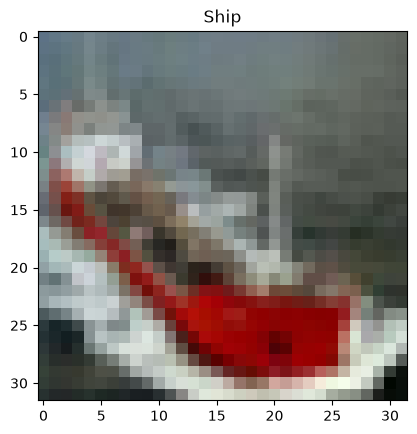

In [3]:
plt.imshow(X_train[465])
plt.title(classes_name[int(y_train[465, 0])])
plt.show()

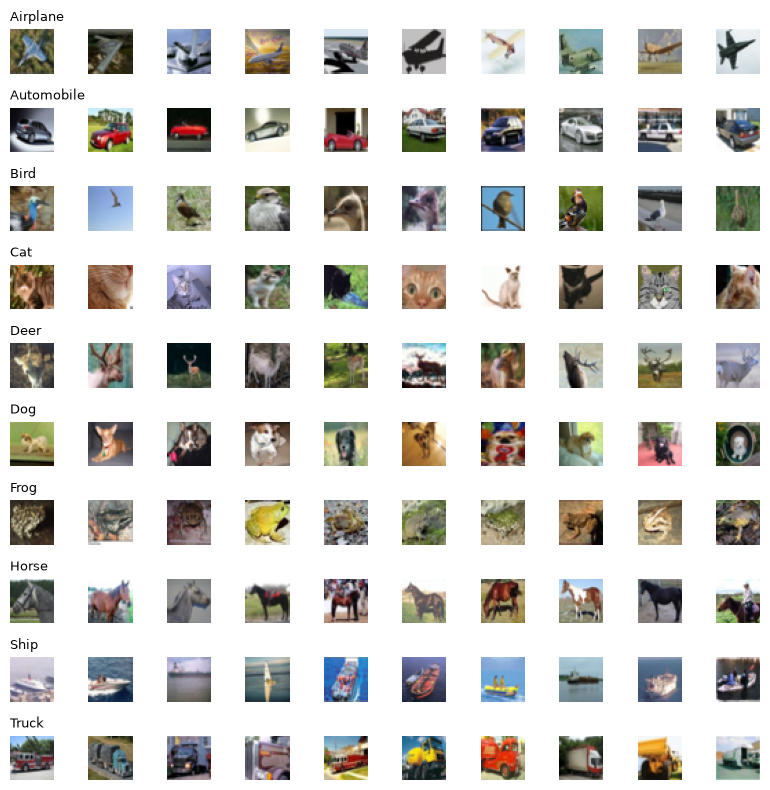

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(10, 10, figsize=(8, 8))
for k in range(10):
    idx = rng.choice(np.where(y_train.ravel() == k)[0], size=10, replace=False)
    for j, i in enumerate(idx):
        axes[k, j].imshow(X_train[i])
        axes[k, j].axis("off")
    axes[k, 0].set_title(classes_name[k], fontsize=9, loc="left")

plt.tight_layout()
plt.savefig(FIG_DIR / "samples_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

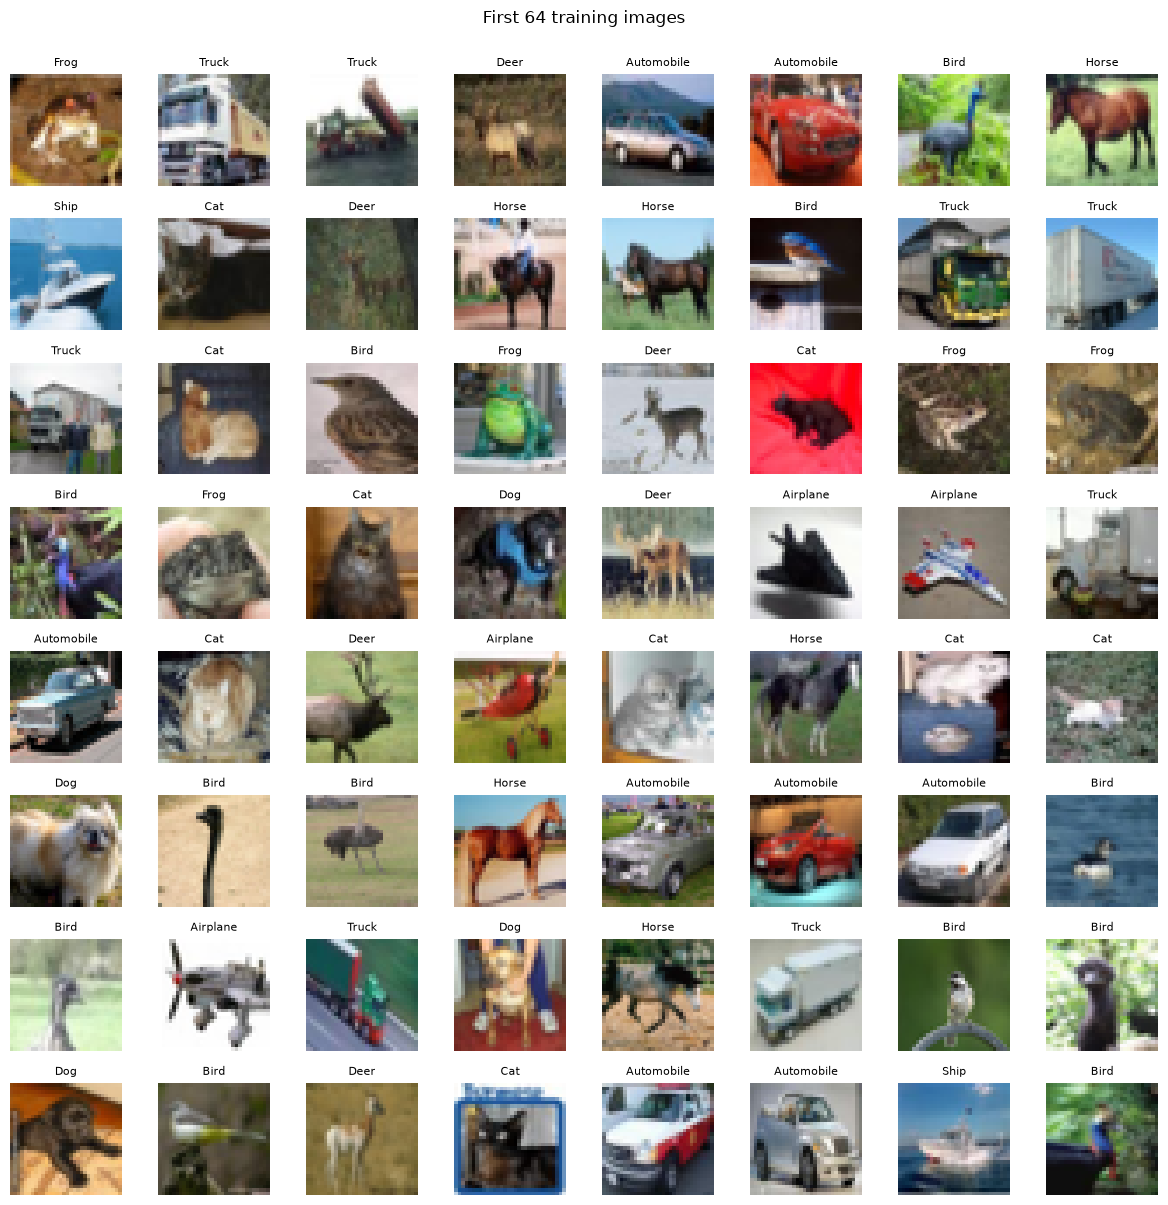

In [5]:
fig, axes = plt.subplots(8, 8, figsize=(12, 12))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i])
    ax.set_title(classes_name[y_train[i, 0]], fontsize=8)
    ax.axis("off")

plt.suptitle("First 64 training images", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
counts = pd.DataFrame({
    "train": pd.Series(y_train.ravel()).value_counts().sort_index(),
    "test": pd.Series(y_test.ravel()).value_counts().sort_index(),
})
counts.index = classes_name
counts

,train,test
Airplane,5000,1000
Automobile,5000,1000
Bird,5000,1000
Cat,5000,1000
Deer,5000,1000
Dog,5000,1000
Frog,5000,1000
Horse,5000,1000
Ship,5000,1000
Truck,5000,1000


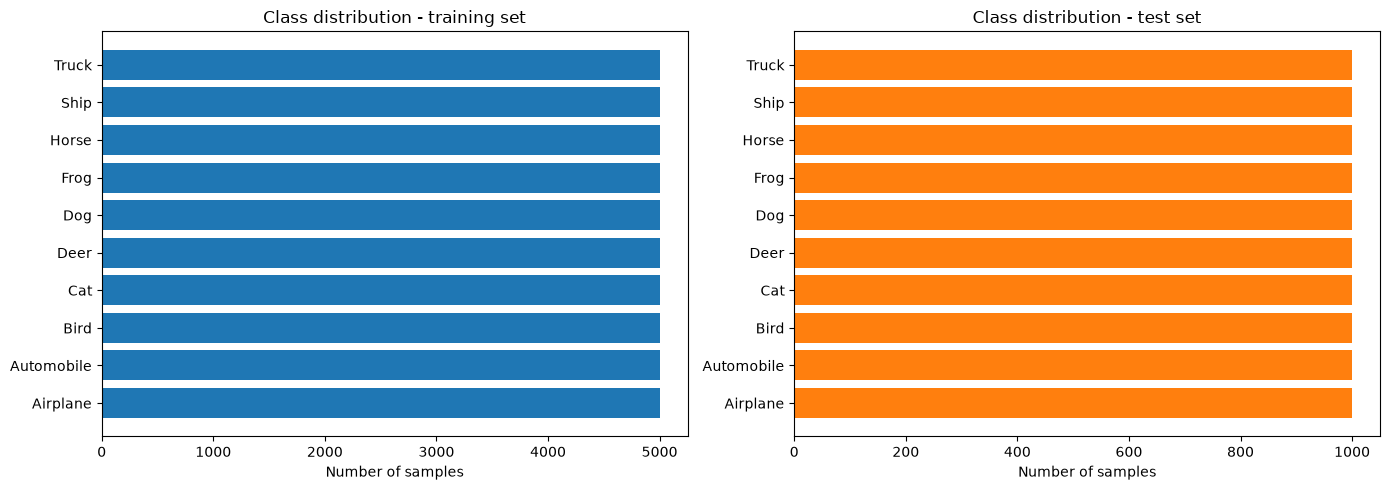

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(classes_name, counts["train"], color="tab:blue")
axes[0].set_title("Class distribution - training set")

axes[1].barh(classes_name, counts["test"], color="tab:orange")
axes[1].set_title("Class distribution - test set")

for ax in axes:
    ax.set_xlabel("Number of samples")

plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
print(f"X_train: min={X_train.min()}  max={X_train.max()}")
print(f"X_test : min={X_test.min()}  max={X_test.max()}")
print(f"y_train: min={y_train.min()}  max={y_train.max()}")
print(f"y_test : min={y_test.min()}  max={y_test.max()}")

X_train: min=0  max=255
X_test : min=0  max=255
y_train: min=0  max=9
y_test : min=0  max=9


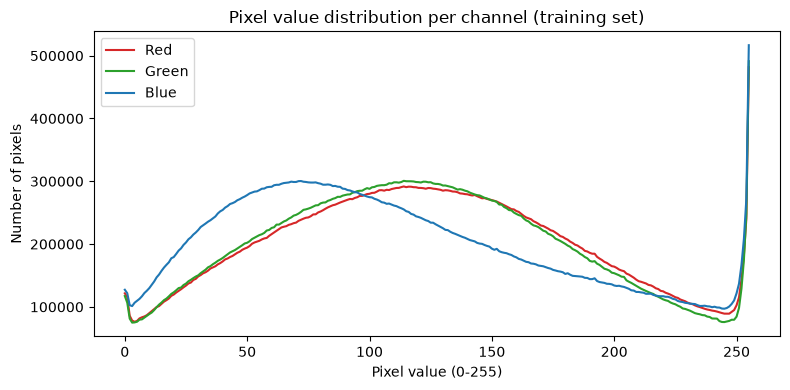

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for c, (name, color) in enumerate(zip(["Red", "Green", "Blue"], ["tab:red", "tab:green", "tab:blue"])):
    counts_c = np.bincount(X_train[..., c].ravel(), minlength=256)
    ax.plot(counts_c, color=color, label=name)

ax.set_xlabel("Pixel value (0-255)")
ax.set_ylabel("Number of pixels")
ax.set_title("Pixel value distribution per channel (training set)")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# Computed on the training set only (the test set must not influence preprocessing)
channel_mean = X_train.mean(axis=(0, 1, 2))
channel_std = X_train.std(axis=(0, 1, 2))
print("Mean per channel (R, G, B):", channel_mean.round(2))
print("Std  per channel (R, G, B):", channel_std.round(2))

Mean per channel (R, G, B): [125.31 122.95 113.87]
Std  per channel (R, G, B): [62.99 62.09 66.7 ]


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🔧 Preprocessing</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
    
<li>Step 1: Separating a 10% validation set.</li> 
<li>Step 2: Scaling pixels to the range [0, 1].</li>
<li>Step 3: Step 3: Encoding tags using One hot Encoding.</li> 

</ul>
</div>

In [11]:
# Step 1: Separating a 10% validation set
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train, y_train,
    test_size=0.1,
    stratify=y_train.ravel(),
    random_state=RANDOM_STATE,
)

print("Train part:", X_train_part.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Train part: (45000, 32, 32, 3) | Validation: (5000, 32, 32, 3) | Test: (10000, 32, 32, 3)


In [12]:
# Step 2: Scaling pixels to the range [0, 1]
def prepare_images(X):
    """uint8 images (N, 32, 32, 3) -> float32 in [0, 1], flattened to (N, 3072)."""
    return (X.astype("float32") / 255.0).reshape(len(X), -1)

X_train_flat = prepare_images(X_train_part)
X_val_flat = prepare_images(X_val)
X_test_flat = prepare_images(X_test)

for name, arr in [("X_train_flat", X_train_flat), ("X_val_flat", X_val_flat), ("X_test_flat", X_test_flat)]:
    print(f"{name:12s} shape={arr.shape}  dtype={arr.dtype}  min={arr.min():.1f}  max={arr.max():.1f}")

X_train_flat shape=(45000, 3072)  dtype=float32  min=0.0  max=1.0
X_val_flat   shape=(5000, 3072)  dtype=float32  min=0.0  max=1.0
X_test_flat  shape=(10000, 3072)  dtype=float32  min=0.0  max=1.0


In [13]:
# Step 3: Encoding tags using One hot Encoding
y_train_cat = to_categorical(y_train_part, num_classes=10)
y_val_cat = to_categorical(y_val, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print("y_train_cat:", y_train_cat.shape, "| y_val_cat:", y_val_cat.shape, "| y_test_cat:", y_test_cat.shape)

y_train_cat: (45000, 10) | y_val_cat: (5000, 10) | y_test_cat: (10000, 10)


In [14]:
pd.DataFrame({
    "train_part": np.bincount(y_train_part.ravel(), minlength=10),
    "validation": np.bincount(y_val.ravel(), minlength=10),
}, index=classes_name)

,train_part,validation
Airplane,4500,500
Automobile,4500,500
Bird,4500,500
Cat,4500,500
Deer,4500,500
Dog,4500,500
Frog,4500,500
Horse,4500,500
Ship,4500,500
Truck,4500,500


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🤖 MLP Model</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<li>Step 1: Build an all-connected network</li>
<li>Step 2: Compile with learning rete, evaluation criteria and CrossEntropy</li>
<li>Step 3: Fitting on training data validation date sets</li>
</div>

In [15]:
# Step 1: Build an all-connected network
model = Sequential([
    Input(shape=(3072,)),
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

I0000 00:00:1795691103.763094   66617 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6100 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Step 2: Compile with learning rete, evaluation criteria and CrossEntropy
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [17]:
# Step 3: Fitting on training data validation date sets
history = model.fit(
    X_train_flat, y_train_cat,
    validation_data=(X_val_flat, y_val_cat),
    epochs=70,
    batch_size=64,
    verbose=2,
)

model.save("../models/mlp.keras")

Epoch 1/70


I0000 00:00:1795691106.561969   66690 service.cc:153] XLA service 0x7e4aec032d20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795691106.561998   66690 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2060 SUPER, Compute Capability 7.5 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1795691106.594083   66690 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795691106.759738   66690 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1795691106.802632   66690 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1800__.20
I0000 00:00:1795691108.288358   66690 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1795691109.842187   66691 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1800__.2

704/704 - 6s - 9ms/step - accuracy: 0.2480 - loss: 2.0294 - val_accuracy: 0.3040 - val_loss: 1.8934
Epoch 2/70
704/704 - 2s - 2ms/step - accuracy: 0.2934 - loss: 1.9071 - val_accuracy: 0.3350 - val_loss: 1.8173
Epoch 3/70
704/704 - 2s - 3ms/step - accuracy: 0.3148 - loss: 1.8688 - val_accuracy: 0.3360 - val_loss: 1.8217
Epoch 4/70
704/704 - 2s - 2ms/step - accuracy: 0.3207 - loss: 1.8410 - val_accuracy: 0.3492 - val_loss: 1.7831
Epoch 5/70
704/704 - 2s - 3ms/step - accuracy: 0.3340 - loss: 1.8158 - val_accuracy: 0.3386 - val_loss: 1.8131
Epoch 6/70
704/704 - 2s - 3ms/step - accuracy: 0.3398 - loss: 1.8053 - val_accuracy: 0.3742 - val_loss: 1.7483
Epoch 7/70
704/704 - 2s - 3ms/step - accuracy: 0.3428 - loss: 1.7903 - val_accuracy: 0.3620 - val_loss: 1.7674
Epoch 8/70
704/704 - 2s - 3ms/step - accuracy: 0.3516 - loss: 1.7762 - val_accuracy: 0.3512 - val_loss: 1.7813
Epoch 9/70
704/704 - 2s - 3ms/step - accuracy: 0.3549 - loss: 1.7659 - val_accuracy: 0.3912 - val_loss: 1.7016
Epoch 10/70


In [18]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

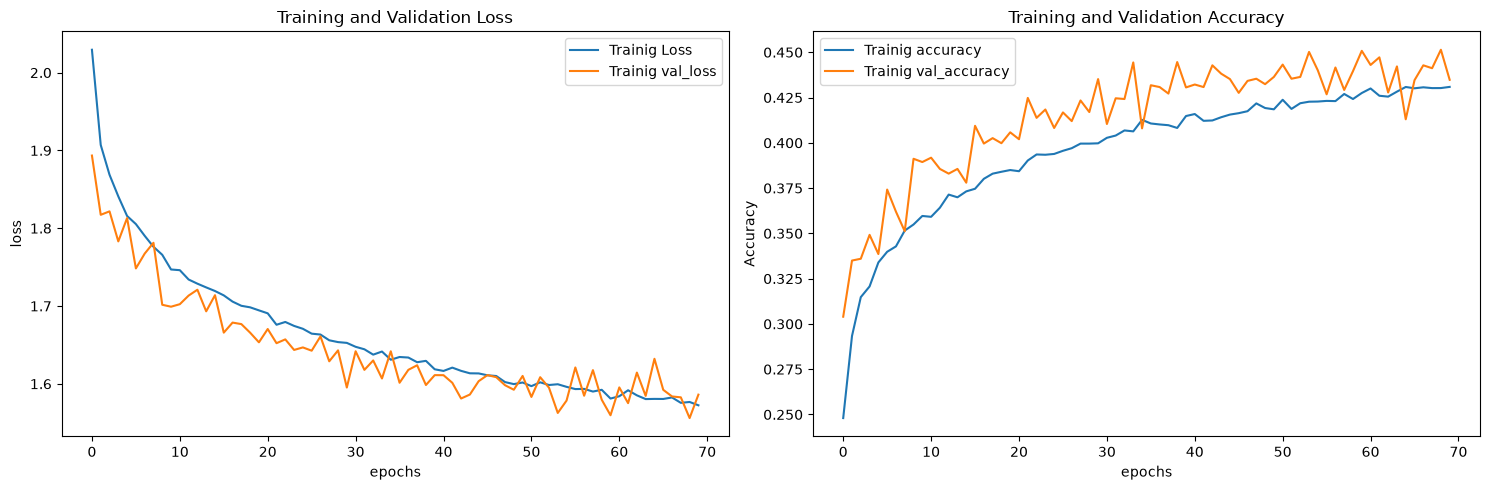

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history.history['loss'], label='Trainig Loss')
axes[0].plot(history.history['val_loss'], label='Trainig val_loss')
axes[0].set_title('Training and Validation Loss')
axes[0].set_xlabel('epochs')
axes[0].set_ylabel('loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Trainig accuracy')
axes[1].plot(history.history['val_accuracy'], label='Trainig val_accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].set_xlabel('epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.savefig(FIG_DIR / "history.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [20]:
# Accuracy and Error rate analysis
test_loss, test_accuracy = model.evaluate(X_test_flat, y_test_cat, verbose=1)

print (f'test loss: {test_loss:.4f}')
print (f'test accuracy: {test_accuracy:.4f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4446 - loss: 1.5711
test loss: 1.5711
test accuracy: 0.4446


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🔍 Evaluation MLP model</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
<li>Step 1: Prediction</li>
<li>Step 2: confusion_matrix</li>
<li>Step 3: classification_report</li>
</ul>
</div>

In [21]:
# Step 1: Prediction
y_pred_prob = model.predict(X_test_flat)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = y_test.ravel()

print("Predictions:", y_pred[:10])
print("Actual Labels:", y_true[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Predictions: [3 9 8 8 4 6 1 6 4 1]
Actual Labels: [3 8 8 0 6 6 1 6 3 1]


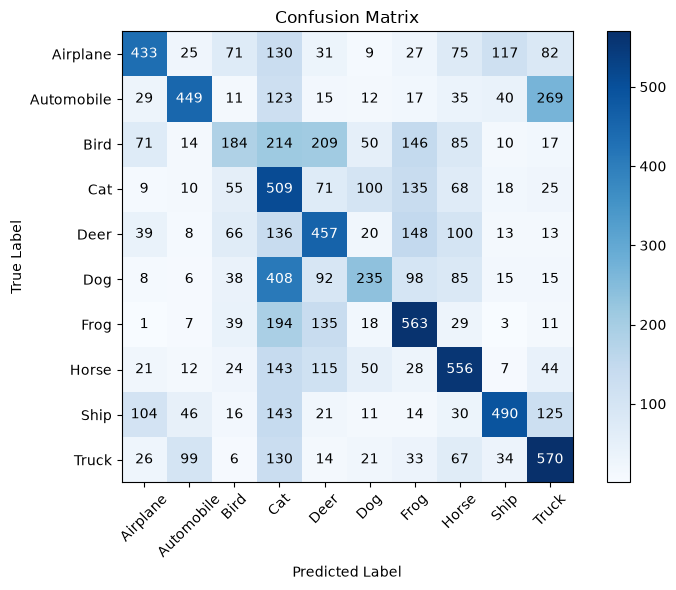

In [22]:
# Step 2: confusion_matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(range(10), classes_name, rotation=45)
plt.yticks(range(10), classes_name)

plt.colorbar()

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j],
                 ha='center',
                 va='center',
                 color='black' if cm[i, j] < cm.max()/2 else 'white')

plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_mlp.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# Step 3: classification_report
report = classification_report(
    y_true,
    y_pred,
    target_names=classes_name,
    digits=4
)

print(report)

              precision    recall  f1-score   support

    Airplane     0.5843    0.4330    0.4974      1000
  Automobile     0.6642    0.4490    0.5358      1000
        Bird     0.3608    0.1840    0.2437      1000
         Cat     0.2390    0.5090    0.3252      1000
        Deer     0.3940    0.4570    0.4231      1000
         Dog     0.4468    0.2350    0.3080      1000
        Frog     0.4657    0.5630    0.5097      1000
       Horse     0.4920    0.5560    0.5221      1000
        Ship     0.6560    0.4900    0.5610      1000
       Truck     0.4868    0.5700    0.5251      1000

    accuracy                         0.4446     10000
   macro avg     0.4789    0.4446    0.4451     10000
weighted avg     0.4789    0.4446    0.4451     10000



In [24]:
# Cheking hte number of errors made
wrong = np.where(y_pred != y_true)[0]
correct = np.where(y_pred == y_true)[0]

print (f'Total Sample        : {len(y_true)}')
print ('-------------------------------')
print (f'Wroung Predictions  : {len(wrong)}')
print (f'Correct Predictions : {len(correct)}')
print ('-------------------------------')
print (f'Accuracy            : {test_accuracy * 100:.2f}%')
print (f'Error               : {100 - test_accuracy * 100:.2f}%')


Total Sample        : 10000
-------------------------------
Wroung Predictions  : 5554
Correct Predictions : 4446
-------------------------------
Accuracy            : 44.46%
Error               : 55.54%


Airplane    : 43.30%
Automobile  : 44.90%
Bird        : 18.40%
Cat         : 50.90%
Deer        : 45.70%
Dog         : 23.50%
Frog        : 56.30%
Horse       : 55.60%
Ship        : 49.00%
Truck       : 57.00%


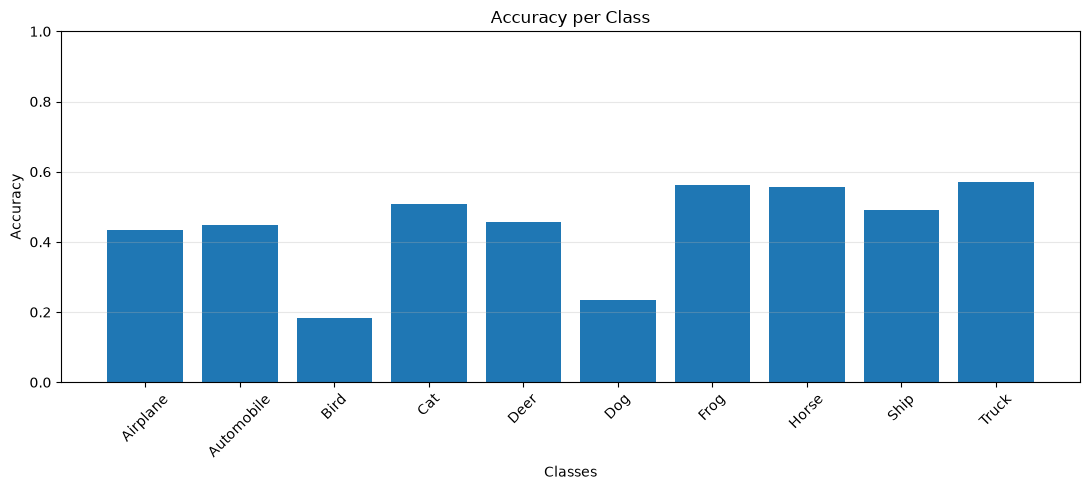

In [25]:
class_accuracy = cm.diagonal() / cm.sum(axis=1)

for name, acc in zip(classes_name, class_accuracy):
    print(f"{name:12s}: {acc:.2%}")

plt.figure(figsize=(11, 5))

plt.bar(classes_name, class_accuracy)

plt.title("Accuracy per Class")
plt.xlabel("Classes")
plt.ylabel("Accuracy")

plt.xticks(rotation=45)
plt.ylim(0, 1)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

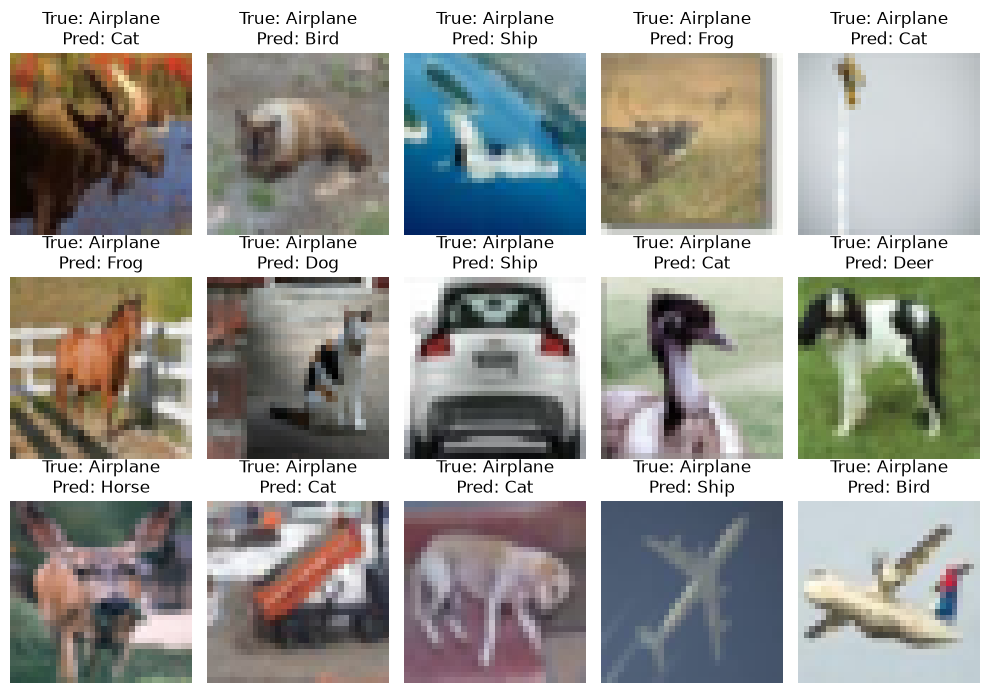

In [26]:
n = min(15, len(wrong))
random_wrong = np.random.choice(wrong, size=n, replace=False)

plt.figure(figsize=(10, 7))

for i, idx in enumerate(random_wrong):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[idx])

    true_label = classes_name[int(y_test.argmax(axis=1)[idx])]
    pred_label = classes_name[int(y_pred[idx])]

    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis('off')

plt.tight_layout()
plt.savefig(FIG_DIR / "wrong-prediction.png", dpi=150, bbox_inches="tight")
plt.show()


## Conclusion

- The baseline MLP classified **4369 of 10,000** test images correctly (**43.69% accuracy**), compared with 10% expected from random guessing among 10 equally sized classes.
- Best recognised classes: [from the classification report]. Hardest classes: [from the classification report].
- No hyperparameter tuning was done for the MLP; the test set was used once, for the final evaluation only.
- Limitation: an MLP flattens each image into a vector of 3072 numbers, so it ignores which pixels are neighbours. A CNN is designed to use that structure, which is the next experiment.


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
padding:35px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
text-align:center;
">

<h1 style="margin-bottom:10px;color:#00E5FF;">🎉 Thank You for rewied</h1>
<hr style="border:1px solid #8A2BE2;opacity:.4;width:70%;margin:auto;">

<br>

<h3 style="color:#E0E0E0;">Thank you for taking the time to explore this notebook.</h3>
<h5 style="font-size:17px;line-height:1.8;color:#CFCFCF;margin-top:20px;">
I hope this project has been useful and informative.<br>
Your feedback and suggestions are always appreciated.</h5>

<br>

<h2 style="color:#00E5FF;">Code • Learn • Build</h2>
</div>